# Hasil akhir: ToMMeR multibahasa, dari masalah sampai perbaikan

Notebook ini **tidak menjalankan model**. Ia membaca berkas hasil yang sudah dihitung di server (folder `data/`) dan membangun
ulang setiap angka di laporan dan PPT. Setiap klaim diberi nomor **K** yang sama dengan `../PETA_KLAIM.md`. Setiap bagian memuat
**pertanyaan → angka → bacaan** (kalimat yang dihitung dari angka, bukan diketik) **→ batas klaim**.

**Alur:**
1. **Apakah ToMMeR memang jelek di bahasa lain?** Diuji di UNER PUD: 1.000 kalimat yang sama dalam 10 bahasa.
2. **Mengapa?** Format dan spasi, batas sebutan, partikel Korea, lapisan; lalu penyebab yang sudah disingkirkan.
3. **Perbaikan: transfer lintas bahasa.** Data latih dan data uji (EDA), hasil, penyebab pola yang aneh, kontrol negatif.
4. **Perbandingan dengan baseline** XLM-R dan GLiNER di bahasa sasaran.
5. **Keterbatasan.**

Bagian 0 memastikan dulu bahwa cara ukur kami sama dengan paper.

| Berkas di `data/` | Dibuat oleh (kode) | Isi |
|---|---|---|
| `prf_semua.csv`, `prf_conll.csv` | `skrip/nilai_prf.py` | P/R/F1 semua model, 21 set; titik ambang 0,5, jumlah tebakan sama, t*, greedy |
| `metrik.csv` | `kode_asli/multibahasa_metrik_semua.py metrik` (semua model; set berformat dari `multibahasa_langkah2-3.py format`) | recall 4 kriteria per model/set, termasuk WikiANN dan probe per lapisan |
| `diagnosis/paralel10.csv`, `spasi.csv`, `ringkas.csv`, `kv1.csv`, `kv2.csv` | notebook `3_diagnosis/3c_L3b_menutup_kelemahan` (asal: `kode_asli/langkah3b.py`) | selisih paralel 10 bahasa, intervensi spasi, nasib sebutan, juri |
| `diagnosis/paralel_ketat.csv`, `ambang.csv`, `lapisan.csv`, `asumsi.txt` | notebook `3_diagnosis/3b_L3_mencari_penyebab` (asal: `multibahasa_langkah2-3.py` `paralel-ketat`, `ambang`, `lapisan`, `asumsi`) | penyebab yang diuji di langkah 3 |
| `diagnosis/precision_juri.csv` | `multibahasa_langkah2-3.py` `juri-sampel`/`juri-hitung` | presisi menurut juri LLM (keterbatasan) |
| `eda_ringkas.csv` | `2_EDA/2_EDA_dataset.ipynb` | statistik 32 dataset (latih dan uji) |
| `selisih_sumber.csv` | `skrip/uji_selisih.py` | selisih langsung sumber A − B |
| `uji_diagonal.csv`, `uji_diagonal_putusan.csv` | `skrip/uji_diagonal.py` | asal selisih: salah batas vs tidak ditebak |
| `tambahan_conll.csv` | `skrip/nilai_tambahan.py` | CoNLL-2003 pada ambang 0,5 dan t* |
| `baseline_prf.csv` | `skrip/baseline_luar.py` → `skrip/nilai_baseline_prf.py` | model akhir vs XLM-R dan GLiNER di bahasa sasaran |
| `xlmr_vs_tommer_v2.csv` | `skrip_anggota/xlmr_eval_v2.py` | XLM-R vs rilis di PUD Inggris (rinci) |

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
DATA, DG, REPRO = Path("data"), Path("data/diagnosis"), Path("../1_reproduksi_CP1/results")
prf = pd.read_csv(DATA / "prf_semua.csv"); met = pd.read_csv(DATA / "metrik.csv"); sel = pd.read_csv(DATA / "selisih_sumber.csv")
pc = pd.read_csv(DATA / "prf_conll.csv"); tc = pd.read_csv(DATA / "tambahan_conll.csv"); xl = pd.read_csv(DATA / "xlmr_vs_tommer_v2.csv")
eda = pd.read_csv(DATA / "eda_ringkas.csv", index_col=0)
p10 = pd.read_csv(DG / "paralel10.csv"); spasi = pd.read_csv(DG / "spasi.csv"); rk = pd.read_csv(DG / "ringkas.csv")
f = lambda v, d=1: f"{v:.{d}f}".replace(".", ",")
sg = lambda v, d=2: ("+" if v > 0 else "−" if v < 0 else "") + f(abs(v), d)
def p(s, g, t="anggaran"):
    r = prf[(prf.set == s) & (prf.grup == g) & (prf.titik == t)]
    return None if r.empty else r.iloc[0]
def dr(s, g, t="anggaran"):                     # ΔR; NaN bila kombinasi set/sumber tidak dinilai
    r = p(s, g, t)
    return np.nan if r is None else r["dR"]
def m(model, s, k="persis", tipe="PLO", dec="threshold"):
    r = met[(met.model == model) & (met.set == s) & (met.kriteria == k) & (met.tipe == tipe) & (met.decoding == dec) & (met.kalimat == "semua")]
    return None if r.empty else r.iloc[0]
print("berkas terbaca:", len(prf), "baris prf,", len(met), "baris metrik,", len(p10), "baris paralel10")

berkas terbaca: 660 baris prf, 28320 baris metrik, 432 baris paralel10


## 0. Prasyarat: cara ukur kami sama dengan paper (K01–K03)
**Pertanyaan.** Sebelum menilai bahasa lain, apakah angka zero-shot paper di 13 benchmark Inggris bisa diulang dengan kode kami?
Kode: `../1_reproduksi_CP1/tommer_repro.sh` (latih) → `eval_table1.py` (nilai), hasil JSON di `../1_reproduksi_CP1/results/`.
Angka paper diketik dari Tabel 1 paper (Llama-3.2-1B, lapisan 6).

In [2]:
NAMA = {"MultiNERD": "MultiNERD", "CoNLL 2003": "CoNLL 2003", "CrossNER_politics": "CrossNER politics", "CrossNER_AI": "CrossNER AI",
        "CrossNER_literature": "CrossNER literature", "CrossNER_science": "CrossNER science", "CrossNER_music": "CrossNER music",
        "ncbi": "NCBI", "FabNER": "FabNER", "WikiNeural": "WikiNeural", "Ontonotes": "OntoNotes", "ACE 2005": "ACE 2005", "GENIA_NER": "GENIA"}
PAPER = {"threshold": [(98.6, 21.7, 35.5), (94.8, 33.6, 49.6), (97.0, 32.4, 48.6), (97.0, 35.0, 51.5), (94.4, 40.3, 56.5), (95.7, 38.2, 54.6),
                       (95.5, 44.1, 60.3), (91.9, 12.7, 22.2), (73.6, 30.1, 42.8), (97.8, 20.7, 34.1), (73.0, 25.5, 37.8), (42.0, 28.7, 34.1), (95.7, 24.8, 39.4)],
         "greedy": [(94.0, 30.0, 45.5), (86.4, 44.7, 58.9), (84.2, 54.5, 66.5), (87.2, 51.2, 64.5), (85.9, 56.6, 68.3), (85.9, 55.1, 67.1),
                    (86.7, 61.7, 72.1), (66.0, 17.1, 27.2), (49.0, 39.7, 43.9), (90.8, 28.2, 43.1), (59.0, 31.4, 40.9), (32.5, 31.9, 32.2), (72.0, 34.6, 46.6)]}
muat = lambda n: json.load(open(REPRO / f"{n}.json"))
def tabel(run):
    rows = []
    for dec in ("threshold", "greedy"):
        for (k, nm), pp in zip(NAMA.items(), PAPER[dec]):
            x = run[f"{dec}/{k}"]
            rows.append(dict(decoding=dec, dataset=nm, R=100 * x["recall"], P=100 * x["precision"], F1=100 * x["f1"], R_paper=pp[0], P_paper=pp[1], F1_paper=pp[2]))
    return pd.DataFrame(rows)
kami, rilis = tabel(muat("own_L6_E8")), tabel(muat("release_L6"))
rata = kami.groupby("decoding")[["R", "P", "F1", "R_paper", "P_paper", "F1_paper"]].mean(); display(rata.round(1))
thr, gr = rata.loc["threshold"], rata.loc["greedy"]
lebih = int((kami[kami.decoding == "threshold"].R.round(1) >= kami[kami.decoding == "threshold"].R_paper).sum())
print(f"K01 Bacaan: recall threshold kami {f(thr.R)} vs paper {f(thr.R_paper)} (≥ paper di {lebih} dari 13 dataset); "
      f"presisi {f(thr.P)} vs {f(thr.P_paper)}; F1 greedy {f(gr.F1)} vs {f(gr.F1_paper)}.")
pas = [(round(r[a], 1), r[b]) for _, r in rilis.iterrows() for a, b in (("R", "R_paper"), ("P", "P_paper"), ("F1", "F1_paper"))]
sama = sum(abs(a - b) < 0.05 for a, b in pas); dekat = sum(abs(a - b) <= 0.5 for a, b in pas)
print(f"K02 Bacaan: checkpoint resmi vs paper: {sama} dari {len(pas)} angka identik setelah dibulatkan, {dekat} dari {len(pas)} berselisih ≤ 0,5 poin "
      "→ cara hitung kami sama dengan paper.")
l1 = tabel(muat("own_L1_E8")).groupby("decoding")[["P", "R", "F1"]].mean()
print("K03 lapisan 1 vs 6 (rata-rata 13 dataset):"); display(pd.concat({"L1": l1, "L6": rata[["P", "R", "F1"]]}).round(1))

,R,P,F1,R_paper,P_paper,F1_paper
decoding,,,,,,
greedy,76.7,37.9,49.5,75.4,41.3,52.1
threshold,91.8,21.9,34.7,88.2,29.8,43.6


K01 Bacaan: recall threshold kami 91,8 vs paper 88,2 (≥ paper di 13 dari 13 dataset); presisi 21,9 vs 29,8; F1 greedy 49,5 vs 52,1.
K02 Bacaan: checkpoint resmi vs paper: 52 dari 78 angka identik setelah dibulatkan, 78 dari 78 berselisih ≤ 0,5 poin → cara hitung kami sama dengan paper.
K03 lapisan 1 vs 6 (rata-rata 13 dataset):


P     R    F1
   decoding                   
L1 greedy     34.5  73.3  46.0
   threshold  21.9  89.6  34.6
L6 greedy     37.9  76.7  49.5
   threshold  21.9  91.8  34.7

**Batas klaim.** Model latih kami bekerja di titik operasi lain (recall lebih tinggi, presisi lebih rendah), jadi bukan "lebih baik".
Yang penting untuk bagian berikutnya adalah K02: checkpoint resmi yang kami nilai ulang cocok dengan paper. **Semua bagian multibahasa
memakai checkpoint resmi ("rilis")**, bukan model latih kami.

## 1. Apakah ToMMeR memang jelek di bahasa lain? (K06, K26)
**Pertanyaan.** Paper melaporkan recall Mandarin 40,7% di WikiANN. Apakah model rilis memang lemah di bahasa non-Latin?

**Cara uji.** UNER PUD berisi 1.000 kalimat yang **sama** (terjemahan) dalam 10 bahasa, dengan kunci PLO. Karena kalimatnya sama,
selisih recall antarbahasa bukan karena isi kalimat. Kriteria `karakter`: tebakan benar bila rentang hurufnya sama dengan kunci.
PUD Korea juga dinilai `per_kata`, karena partikel Korea menempel pada kata (dibahas di bagian 2c).
Kode: `skrip/nilai_prf.py` (P/R/F1) dan notebook `3_diagnosis/3c_L3b_menutup_kelemahan` (selisih berpasangan terhadap Inggris).

,P,R,ci_R,F1,tebakan,emas,P_greedy,R_greedy,F1_greedy,tebakan_greedy
set,,,,,,,,,,
UNER_PUD_en,17.61,96.93,1.21,29.81,5916,1075,22.58,87.35,35.88,4159
UNER_PUD_de,16.05,96.05,1.38,27.50,6218,1039,21.16,88.45,34.15,4343
UNER_PUD_pt,14.49,98.64,0.65,25.26,7483,1099,21.59,90.72,34.88,4617
UNER_PUD_cs,15.62,95.44,1.37,26.84,6160,1008,21.58,85.12,34.43,3976
UNER_PUD_sv,15.64,96.60,1.11,26.92,6355,1029,21.15,90.48,34.29,4401
UNER_PUD_id,14.48,97.39,0.88,25.21,7466,1110,22.00,90.36,35.39,4559
UNER_PUD_ru,18.37,97.01,1.06,30.89,5472,1036,25.01,91.99,39.33,3810
UNER_PUD_zh,18.83,87.62,1.96,30.99,5301,1139,24.85,78.84,37.79,3614
UNER_PUD_ja,24.20,84.35,2.13,37.61,4008,1150,28.69,76.17,41.68,3053


K06 Bacaan: PUD Latin/Kiril 95,4–98,6; Asia Timur 84,3–87,6 (threshold 0,5).


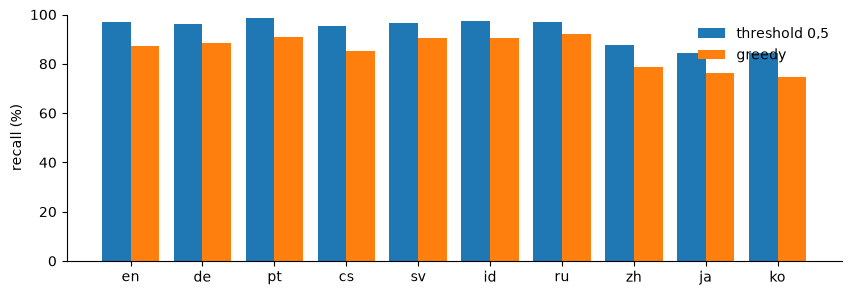

In [3]:
SETS = list(dict.fromkeys(prf.set))
r05 = prf[(prf.grup == "rilis") & (prf.titik == "rilis0.5")].set_index("set")[["P", "R", "ci_R", "F1", "tebakan", "emas"]]
rg = prf[(prf.grup == "rilis") & (prf.titik == "greedy")].set_index("set")[["P", "R", "F1", "tebakan"]].add_suffix("_greedy")
t = r05.join(rg).loc[SETS]
pudset = [s for s in SETS if s.startswith("UNER_PUD")]; display(t.loc[pudset])
lat = t.loc[["UNER_PUD_" + k for k in ("en", "de", "pt", "cs", "sv", "id", "ru")], "R"]; asia = t.loc[["UNER_PUD_zh", "UNER_PUD_ja", "UNER_PUD_ko"], "R"]
print(f"K06 Bacaan: PUD Latin/Kiril {f(lat.min())}–{f(lat.max())}; Asia Timur {f(asia.min())}–{f(asia.max())} (threshold 0,5).")
fig, ax = plt.subplots(figsize=(10, 3.2)); x = np.arange(len(pudset))
ax.bar(x - .2, t.loc[pudset, "R"], .4, label="threshold 0,5"); ax.bar(x + .2, t.loc[pudset, "R_greedy"], .4, label="greedy")
ax.set_xticks(x); ax.set_xticklabels([s[-2:] for s in pudset]); ax.set_ylabel("recall (%)"); ax.set_ylim(0, 100); ax.legend(frameon=False); plt.show()

In [4]:
q = p10[(p10.model == "release") & (p10.tipe == "PLO") & (p10.entitas == "semua")]
kar = q[((q.bahasa != "ko") & (q.kriteria == "karakter")) | ((q.bahasa == "ko") & (q.kriteria == "per_kata"))].set_index("bahasa")[["kalimat", "R_en", "R", "dR", "ci95_dR"]]
display(kar)
beda = kar[(kar.dR + kar.ci95_dR) < 0]
print(f"K26 Bacaan: selisih berpasangan terhadap Inggris pada kalimat yang sama (± CI 95%): " +
      "; ".join(f"{b} {sg(r.dR)} ± {f(r.ci95_dR, 2)}" for b, r in kar.iterrows()) + ".")
print(f"    Hanya {', '.join(beda.index)} yang tertinggal dengan CI di bawah nol. Rusia (aksara Kiril) setara Inggris.")
pk = pd.read_csv(DG / "paralel_ketat.csv"); z = pk[(pk.bahasa == "zh") & (pk.decoding == "threshold")].set_index("kalimat")
print(f"    Cek label terjemahan (kriteria persis): Mandarin vs Inggris semua kalimat {sg(z.loc['semua_kalimat','dR'])} ± {f(z.loc['semua_kalimat','ci95_dR'],2)}; "
      f"hanya kalimat yang labelnya sama di kedua bahasa {sg(z.loc['label_sama','dR'])} ± {f(z.loc['label_sama','ci95_dR'],2)} → selisih bukan karena beda label terjemahan.")

,kalimat,R_en,R,dR,ci95_dR
bahasa,,,,,
de,999,97.02,96.15,-0.87,1.75
pt,999,97.02,98.63,1.61,1.42
cs,999,97.02,95.53,-1.49,1.87
sv,998,97.02,96.59,-0.43,1.48
id,999,97.02,97.48,0.45,1.46
ru,999,97.02,97.00,-0.02,1.68
zh,999,97.02,87.60,-9.42,2.24
ja,999,97.02,84.42,-12.60,2.46
ko,999,97.21,84.37,-12.83,2.54


K26 Bacaan: selisih berpasangan terhadap Inggris pada kalimat yang sama (± CI 95%): de −0,87 ± 1,75; pt +1,61 ± 1,42; cs −1,49 ± 1,87; sv −0,43 ± 1,48; id +0,45 ± 1,46; ru −0,02 ± 1,68; zh −9,42 ± 2,24; ja −12,60 ± 2,46; ko −12,83 ± 2,54.
    Hanya zh, ja, ko yang tertinggal dengan CI di bawah nol. Rusia (aksara Kiril) setara Inggris.
    Cek label terjemahan (kriteria persis): Mandarin vs Inggris semua kalimat −12,24 ± 2,42; hanya kalimat yang labelnya sama di kedua bahasa −11,99 ± 3,06 → selisih bukan karena beda label terjemahan.


**Jawaban bagian 1: ya.** Pada kalimat yang sama, ToMMeR kehilangan ±9–14 poin recall di Mandarin, Jepang, dan Korea. Bahasa Latin
dan Rusia setara Inggris. Selisih ini milik model, bukan isi kalimat atau label terjemahan.

**Batas klaim.** Presisi rendah di semua bahasa, termasuk Inggris, karena kunci PUD hanya berisi PLO sedangkan ToMMeR menandai semua
sebutan. Jadi ukuran utamanya recall (lihat bagian 5).

## 2. Mengapa ToMMeR lemah di Mandarin, Jepang, dan Korea?
Ada lima dugaan. Masing-masing diuji dengan data:

| Dugaan | Uji | Bagian |
|---|---|---|
| Format input dan **spasi** | WikiANN dengan dua format; menambah atau menghapus spasi pada kalimat yang sama | 2a |
| **Batas** sebutan (tebakan terlalu panjang) | nasib tiap sebutan kunci; juri menilai tebakan yang "salah" | 2b |
| **Partikel** Korea | kriteria per kata vs per huruf | 2c |
| Lapisan 6 terlalu dangkal | probe rilis untuk setiap lapisan 0–15 | 2d |
| Aksara, tokenizer, ambang, label terjemahan | Rusia; token tidak sejajar; ambang per bahasa; kalimat berlabel sama | 2e |

### 2a. Format dan spasi (K08, K09)
**Uji 1, format WikiANN.** WikiANN Mandarin di benchmark paper ditulis dengan **spasi di antara setiap huruf**. Kami menilai teks yang
sama dalam format berspasi dan alami. Kode: `kode_asli/multibahasa_langkah2-3.py format` (set berformat) → `kode_asli/multibahasa_metrik_semua.py metrik` → `metrik.csv`.

In [5]:
WK = ["WikiANN_es_spasi", "WikiANN_fr_spasi", "WikiANN_de_spasi", "WikiANN_en_spasi", "WikiANN_zh_spasi", "WikiANN_zh_alami", "WikiANN_ja_spasi", "WikiANN_ja_alami"]
w = pd.DataFrame([dict(set=s, **{f"{k}_{d}": m("release", s, k, "semua_tipe", d)["R"] for k in ("persis",) for d in ("threshold", "greedy")}) for s in WK]).set_index("set")
display(w)
print(f"K08 Bacaan: Mandarin format berspasi {f(w.loc['WikiANN_zh_spasi','persis_threshold'])} (= angka paper 40,7) vs teks alami "
      f"{f(w.loc['WikiANN_zh_alami','persis_threshold'])}. Angka 40,7 di paper terutama efek format, bukan kemampuan Mandarin.")

,persis_threshold,persis_greedy
set,,
WikiANN_es_spasi,85.36,74.20
WikiANN_fr_spasi,86.94,76.06
WikiANN_de_spasi,91.40,83.76
WikiANN_en_spasi,84.40,75.94
WikiANN_zh_spasi,40.72,23.98
WikiANN_zh_alami,75.77,62.43
WikiANN_ja_spasi,54.14,35.40
WikiANN_ja_alami,75.54,67.35


K08 Bacaan: Mandarin format berspasi 40,7 (= angka paper 40,7) vs teks alami 75,8. Angka 40,7 di paper terutama efek format, bukan kemampuan Mandarin.


**Uji 2, intervensi spasi pada kalimat yang sama.** Kalimatnya sama, hanya spasinya yang diubah:
- Mandarin dan Jepang **diberi** spasi lewat segmentasi kata;
- Inggris, Rusia, dan Indonesia **dihapus** spasinya.

Kunci dan tebakan dinilai dengan kriteria karakter, model rilis, ambang 0,5. Kode: notebook `3_diagnosis/3c_L3b_menutup_kelemahan` bagian
intervensi (asal: `kode_asli/langkah3b.py`) → `diagnosis/spasi.csv`.

In [6]:
sp = spasi[spasi.model == "release"].set_index("intervensi")[["alami", "R_alami", "R_intervensi", "dR", "ci95_dR", "alami_terlalu_panjang", "intervensi_terlalu_panjang"]]
display(sp)
gap = {"UNER_PUD_zh": -kar.loc["zh", "dR"], "UNER_PUD_ja": -kar.loc["ja", "dR"]}
tutup = {s: 100 * sp[sp.alami == s].dR.iloc[0] / g for s, g in gap.items()}
print("K09 Bacaan: memberi spasi menaikkan recall " + "; ".join(f"{r.alami[-2:] if 'PUD' in r.alami else 'GSDSIMP'} {sg(r.dR)} ± {f(r.ci95_dR, 2)}" for _, r in sp[sp.dR > 0].iterrows())
      + "; menghapus spasi menjatuhkan " + "; ".join(f"{r.alami[-2:]} {sg(r.dR)} ± {f(r.ci95_dR, 2)}" for _, r in sp[sp.dR < 0].iterrows()) + ".")
print(f"    Spasi menutup {f(tutup['UNER_PUD_ja'], 0)}% selisih Jepang−Inggris dan {f(tutup['UNER_PUD_zh'], 0)}% selisih Mandarin−Inggris. "
      f"Tebakan terlalu panjang di PUD Mandarin turun dari {f(sp.loc['UNER_PUD_zh_spasi','alami_terlalu_panjang'])}% ke {f(sp.loc['UNER_PUD_zh_spasi','intervensi_terlalu_panjang'])}%.")
IV = [("UNER_PUD_ja", "UNER_PUD_ja_spasi"), ("UNER_PUD_zh", "UNER_PUD_zh_spasi"), ("UNER_PUD_en", "UNER_PUD_en_tanpa_spasi"), ("UNER_PUD_ru", "UNER_PUD_ru_tanpa_spasi")]
ivg = {b: m("release", b, "tepi_bersih", dec="greedy")["R"] - m("release", a, "tepi_bersih", dec="greedy")["R"] for a, b in IV}
print("    Greedy (metrik.csv, tepi bersih): " + "; ".join(f"{b.replace('UNER_PUD_', '')} {sg(v)}" for b, v in ivg.items())
      + " → menghapus spasi tetap menjatuhkan; menambah spasi tidak membantu pada greedy.")

,alami,R_alami,R_intervensi,dR,ci95_dR,alami_terlalu_panjang,intervensi_terlalu_panjang
intervensi,,,,,,,
UNER_PUD_zh_spasi,UNER_PUD_zh,87.62,91.92,4.30,1.88,6.41,3.69
UNER_GSDSIMP_zh_spasi,UNER_GSDSIMP_zh,86.63,88.99,2.36,2.50,7.99,4.33
UNER_PUD_ja_spasi,UNER_PUD_ja,84.35,92.17,7.83,2.35,5.57,2.52
UNER_PUD_en_tanpa_spasi,UNER_PUD_en,96.93,70.79,-26.14,2.81,1.86,13.86
UNER_PUD_ru_tanpa_spasi,UNER_PUD_ru,97.01,47.88,-49.13,3.27,1.64,18.34
UNER_PUD_id_tanpa_spasi,UNER_PUD_id,97.39,45.95,-51.44,3.02,1.53,23.42


K09 Bacaan: memberi spasi menaikkan recall zh +4,30 ± 1,88; GSDSIMP +2,36 ± 2,50; ja +7,83 ± 2,35; menghapus spasi menjatuhkan en −26,14 ± 2,81; ru −49,13 ± 3,27; id −51,44 ± 3,02.
    Spasi menutup 62% selisih Jepang−Inggris dan 46% selisih Mandarin−Inggris. Tebakan terlalu panjang di PUD Mandarin turun dari 6,4% ke 3,7%.
    Greedy (metrik.csv, tepi bersih): ja_spasi −3,13; zh_spasi −1,49; en_tanpa_spasi −23,16; ru_tanpa_spasi −50,77 → menghapus spasi tetap menjatuhkan; menambah spasi tidak membantu pada greedy.


**Bacaan 2a.** Spasi adalah penanda batas kata bagi ToMMeR. Bahasa tanpa spasi kehilangan penanda itu, dan spasi buatan menutup
sebagian besar selisih Jepang dan sebagian selisih Mandarin.
**Batas klaim.** Teks tanpa spasi juga tidak wajar bagi LLM, jadi efek "penanda batas" belum terpisah dari efek "teks tidak wajar".
Pada greedy, menambah spasi tidak membantu; penyebabnya belum diketahui.

### 2b. Batas sebutan: tebakan terlalu panjang (K27)
**Pertanyaan.** Apakah ToMMeR tidak melihat sebutan Asia Timur, atau melihatnya tetapi batasnya meleset?
Ada tiga bukti:
- kriteria **tumpang** (asal tebakan menyentuh kunci) vs **karakter** (batas harus sama);
- nasib tiap sebutan kunci;
- **juri** (LLM; belum divalidasi manusia) yang menilai apakah tebakan "terlalu panjang" sebenarnya sebutan sah.

Kode: notebook `3_diagnosis/3c_L3b_menutup_kelemahan` → `diagnosis/paralel10.csv`, `ringkas.csv`, `kv1.csv`.

In [7]:
tp_ = q[q.kriteria == "tumpang"].set_index("bahasa")["dR"]
bk = rk[(rk.model == "release") & (rk.entitas == "semua") & rk.set.isin(["UNER_PUD_en", "UNER_PUD_zh", "UNER_PUD_ja", "UNER_PUD_ko"])].set_index("set")
display(bk[["R_karakter", "R_tumpang", "BK_terlalu_panjang", "BK_terlalu_pendek", "BK_bersilangan", "BK_tidak_ada_tebakan"]])
kv1 = pd.read_csv(DG / "kv1.csv").set_index("set"); display(kv1)
print("K27 Bacaan: selisih terhadap Inggris dengan kriteria tumpang jauh lebih kecil: " +
      "; ".join(f"{b} {sg(kar.loc[b,'dR'])} → {sg(tp_[b])}" for b in ("zh", "ja", "ko")) + " (per huruf/per kata → tumpang).")
print(f"    Recall tumpang PUD Mandarin {f(bk.loc['UNER_PUD_zh','R_tumpang'])}, Jepang {f(bk.loc['UNER_PUD_ja','R_tumpang'])}, Korea {f(bk.loc['UNER_PUD_ko','R_tumpang'])}: "
      "model menyentuh hampir semua sebutan; yang salah sebagian besar batasnya.")
print(f"    Mandarin: {f(bk.loc['UNER_PUD_zh','BK_terlalu_panjang'])}% sebutan kunci ditebak terlalu panjang (Inggris {f(bk.loc['UNER_PUD_en','BK_terlalu_panjang'])}%). "
      f"Menurut juri, {f(kv1.loc['UNER_PUD_zh','KV1_pct_sah'], 0)}% (Mandarin) dan {f(kv1.loc['UNER_PUD_ja','KV1_pct_sah'], 0)}% (Jepang) tebakan terlalu panjang itu sebutan sah: "
      "sebagian 'kesalahan' kemungkinan beda aturan penandaan, bukan kegagalan model (juri belum divalidasi manusia).")

,R_karakter,R_tumpang,BK_terlalu_panjang,BK_terlalu_pendek,BK_bersilangan,BK_tidak_ada_tebakan
set,,,,,,
UNER_PUD_en,96.93,99.81,1.86,1.21,0.00,0.00
UNER_PUD_zh,87.62,95.79,6.41,1.76,0.00,4.21
UNER_PUD_ja,84.35,92.35,5.57,2.43,0.17,7.48
UNER_PUD_ko,40.53,91.47,4.61,45.65,0.77,8.45


,n,KV1_pct_sah,ci95
set,,,
UNER_PUD_en,18,94.4,10.6
UNER_PUD_zh,74,77.0,9.6
UNER_PUD_ja,67,88.1,7.8
UNER_GSDSIMP_zh,60,88.3,8.1
KLUE_ko,150,82.7,6.1


K27 Bacaan: selisih terhadap Inggris dengan kriteria tumpang jauh lebih kecil: zh −9,42 → −4,04; ja −12,60 → −7,47; ko −12,83 → −8,35 (per huruf/per kata → tumpang).
    Recall tumpang PUD Mandarin 95,8, Jepang 92,3, Korea 91,5: model menyentuh hampir semua sebutan; yang salah sebagian besar batasnya.
    Mandarin: 6,4% sebutan kunci ditebak terlalu panjang (Inggris 1,9%). Menurut juri, 77% (Mandarin) dan 88% (Jepang) tebakan terlalu panjang itu sebutan sah: sebagian 'kesalahan' kemungkinan beda aturan penandaan, bukan kegagalan model (juri belum divalidasi manusia).


### 2c. Partikel Korea (K07)
Korea berspasi, tetapi partikel menempel pada kata. Contohnya 서울에서, "di Seoul": kuncinya 서울. Kode: `metrik.csv` (4 kriteria)
dan `paralel10.csv` (karakter vs per_kata).

In [8]:
SENS = pd.DataFrame([{**{"set": s}, **{k: (m("release", s, k)["R"] if m("release", s, k) is not None else np.nan) for k in ("persis", "tepi_bersih", "batas_1", "tumpang")}}
                     for s in ["UNER_PUD_en", "UNER_PUD_zh", "UNER_PUD_ja", "UNER_PUD_ko", "MasakhaNER_amh"]]).set_index("set")
display(SENS)
ko_k = q[(q.bahasa == "ko") & (q.kriteria == "karakter")].R.iloc[0]
print(f"K07 Bacaan: PUD Korea per huruf {f(ko_k)} tetapi per kata {f(kar.loc['ko','R'])} dan tumpang {f(SENS.loc['UNER_PUD_ko','tumpang'])}. "
      f"Kunci PUD Korea memuat partikel; ToMMeR (seperti KLUE) menandai kata tanpa partikel. Karena itu PUD Korea dinilai per kata.")

,persis,tepi_bersih,batas_1,tumpang
set,,,,
UNER_PUD_en,96.93,97.30,98.70,99.81
UNER_PUD_zh,84.81,87.71,90.17,95.87
UNER_PUD_ja,83.04,84.35,87.30,92.52
UNER_PUD_ko,38.65,40.53,84.98,91.47
MasakhaNER_amh,0.00,37.17,1.11,90.27


K07 Bacaan: PUD Korea per huruf 40,6 tetapi per kata 84,4 dan tumpang 91,5. Kunci PUD Korea memuat partikel; ToMMeR (seperti KLUE) menandai kata tanpa partikel. Karena itu PUD Korea dinilai per kata.


### 2d. Lapisan (K10)
**Pertanyaan.** Paper memakai lapisan 6. Apakah lapisan lain lebih baik untuk Mandarin? Kode: notebook `3_diagnosis/3b_L3_mencari_penyebab`
bagian D (probe rilis penulis untuk setiap lapisan) → `metrik.csv`, `diagnosis/lapisan.csv`.

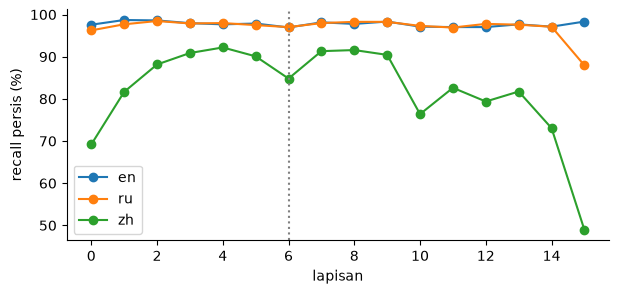

K10 Bacaan: recall Mandarin di lapisan 0 69,2, puncak lapisan 4 (92,2), lapisan 15 48,9; Inggris datar 96,9–98,7.
    Validasi silang (F1): lapisan terbaik untuk PUD Mandarin 14/14 (F1 +6,56 ± 1,40), untuk Inggris tetap 6 → lapisan 6 bukan pilihan terbaik untuk Mandarin, tetapi ini penyebab sampingan (perbaikan kami tetap di lapisan 6).


In [9]:
lap = pd.DataFrame([dict(lapisan=i, **{f"{b}": m("release" if i == 6 else f"lapisan{i:02d}", s)["R"] for s, b in (("UNER_PUD_en", "en"), ("UNER_PUD_ru", "ru"), ("UNER_PUD_zh", "zh"))}) for i in range(16)]).set_index("lapisan")
lapcv = pd.read_csv(DG / "lapisan.csv").set_index("set")
fig, ax = plt.subplots(figsize=(7, 3)); lap.plot(ax=ax, marker="o"); ax.set_ylabel("recall persis (%)"); ax.axvline(6, ls=":", c="grey"); plt.show()
print(f"K10 Bacaan: recall Mandarin di lapisan 0 {f(lap.loc[0,'zh'])}, puncak lapisan {int(lap.zh.idxmax())} ({f(lap.zh.max())}), lapisan 15 {f(lap.loc[15,'zh'])}; "
      f"Inggris datar {f(lap.en.min())}–{f(lap.en.max())}.")
print(f"    Validasi silang (F1): lapisan terbaik untuk PUD Mandarin {lapcv.loc['UNER_PUD_zh','lapisan_terpilih']} (F1 {sg(lapcv.loc['UNER_PUD_zh','dF1'])} ± {f(lapcv.loc['UNER_PUD_zh','ci95_dF1'],2)}), "
      f"untuk Inggris tetap 6 → lapisan 6 bukan pilihan terbaik untuk Mandarin, tetapi ini penyebab sampingan (perbaikan kami tetap di lapisan 6).")

### 2e. Yang sudah disingkirkan (K28)
Kode: notebook `3_diagnosis/3b_L3_mencari_penyebab` (T tokenizer, A ambang) → `diagnosis/asumsi.txt`, `ambang.csv`; paralel ketat di bagian 1.

In [10]:
print(open(DG / "asumsi.txt", encoding="utf8").read().split("\n== B.")[0])
amb = pd.read_csv(DG / "ambang.csv").set_index("set")[["R_0_5", "ambang_terpilih", "R_silang", "R_maks_ambang_0_1"]]; display(amb)
print("K28 Bacaan:")
print(f"  - aksara: Rusia (Kiril) {sg(kar.loc['ru','dR'])} ± {f(kar.loc['ru','ci95_dR'],2)} terhadap Inggris → aksara non-Latin bukan penyebab;")
print("  - tokenizer: sebutan yang tepinya tidak sejajar dengan token hanya 1,5% di PUD Mandarin (kolom T), terlalu sedikit untuk menjelaskan selisih 9 poin;")
print(f"  - ambang: ambang terbaik per bahasa (validasi silang) sama dengan Inggris ({amb.loc['UNER_PUD_zh','ambang_terpilih']}); bahkan pada ambang 0,1 "
      f"recall Mandarin {f(amb.loc['UNER_PUD_zh','R_maks_ambang_0_1'])} vs Inggris {f(amb.loc['UNER_PUD_en','R_maks_ambang_0_1'])} → bukan masalah ambang;")
print("  - label terjemahan: selisih Mandarin sama besar pada kalimat yang labelnya identik (bagian 1).")

set              | T tidak sejajar % (kiri/kanan), R sejajar vs tidak | A emas terlewat: p<=0.1 / 0.1-0.3 / 0.3-0.5 % | K tebakan per kalimat: berentitas vs kosong
UNER_PUD_en      |   0.4 ( 0.3/ 0.1)  R  97.2 vs  25.0 |  63.6 /   9.1 /  27.3 |  6.65 vs  4.88
UNER_PUD_sv      |   0.3 ( 0.2/ 0.1)  R  96.7 vs  66.7 |  62.9 /  28.6 /   8.6 |  7.04 vs  5.43
UNER_PUD_ru      |   0.1 ( 0.0/ 0.1)  R  97.1 vs   0.0 |  61.3 /  19.4 /  19.4 |  6.39 vs  4.25
UNER_PUD_zh      |   1.5 ( 1.1/ 0.4)  R  85.0 vs  70.6 |  53.8 /  26.0 /  20.2 |  6.19 vs  4.02
UNER_GSDSIMP_zh  |   1.8 ( 1.8/ 0.0)  R  85.2 vs  71.4 |  56.5 /  23.5 /  20.0 |  7.87 vs  6.01
MSRA_zh          |   1.6 ( 0.7/ 0.9)  R  74.9 vs  37.5 |  65.6 /  20.4 /  14.0 | 10.51 vs  5.83
Stockmark_ja     |   6.6 ( 4.4/ 2.3)  R  84.4 vs  61.6 |  57.3 /  25.4 /  17.3 |  6.26 vs  3.34
KLUE_ko          |   5.6 ( 0.1/ 5.4)  R  57.8 vs  20.0 |  75.1 /  15.0 /  10.0 |  5.49 vs  0.00
NER_UI_id        |   0.0 ( 0.0/ 0.0)  R  96.4 vs   nan |  48.4 /  23

,R_0_5,ambang_terpilih,R_silang,R_maks_ambang_0_1
set,,,,
UNER_PUD_en,96.93,0.9/0.9,95.44,98.05
UNER_PUD_sv,96.60,0.9/0.9,93.20,97.86
UNER_PUD_ru,97.01,0.9/0.9,94.79,98.17
UNER_PUD_zh,84.81,0.9/0.9,75.42,91.83
UNER_GSDSIMP_zh,84.93,0.9/0.9,73.53,91.48
MSRA_zh,74.26,0.9/0.9,63.28,83.11
Stockmark_ja,82.90,0.9/0.9,71.05,90.20
KLUE_ko,55.71,0.8/0.8,48.19,66.76
NER_UI_id,96.40,0.9/0.9,94.14,98.26


K28 Bacaan:
  - aksara: Rusia (Kiril) −0,02 ± 1,68 terhadap Inggris → aksara non-Latin bukan penyebab;
  - tokenizer: sebutan yang tepinya tidak sejajar dengan token hanya 1,5% di PUD Mandarin (kolom T), terlalu sedikit untuk menjelaskan selisih 9 poin;
  - ambang: ambang terbaik per bahasa (validasi silang) sama dengan Inggris (0.9/0.9); bahkan pada ambang 0,1 recall Mandarin 91,8 vs Inggris 98,0 → bukan masalah ambang;
  - label terjemahan: selisih Mandarin sama besar pada kalimat yang labelnya identik (bagian 1).


**Ringkasan penyebab.**

| Penyebab | Bukti | Status |
|---|---|---|
| Tidak ada spasi sebagai penanda batas kata | WikiANN 40,7 → 75,8; spasi buatan menutup ±62% selisih Jepang, ±46% Mandarin; menghapus spasi menjatuhkan Latin 26–51 poin | penyebab utama (efek "teks tidak wajar" belum terpisah) |
| Batas sebutan meleset (terlalu panjang) | selisih tumpang jauh lebih kecil dari selisih per huruf; 77–88% tebakan terlalu panjang sah menurut juri | penyebab utama; sebagian beda aturan penandaan |
| Partikel Korea | per huruf 40,6 vs per kata 84,4 | diatasi dengan penilaian per kata |
| Lapisan 6 | Mandarin memuncak di lapisan 4 | sampingan |
| Aksara, tokenizer, ambang, label terjemahan | Rusia setara; 1,5% tidak sejajar; ambang terbaik sama; kalimat berlabel sama | bukan penyebab |

Karena masalahnya ada di **batas kata**, perbaikan yang dicoba adalah mengajari probe batas kata bahasa tanpa spasi lewat data bahasa
yang mirip, tanpa melatih ulang LLM.

## 3. Perbaikan: transfer lintas bahasa
### 3a. Data latih dan data uji (K05, K22, K23)
**Rancangan.** Probe rilis dilatih-lanjut (Llama tetap beku) dengan Pile-NER, ditambah ±20% sebutan dari satu bahasa sumber.
- Probe `zhA` (sumber Mandarin) lalu diuji di Jepang dan Korea, dan seterusnya.
- **Kontrol** dilatih dengan resep sama tanpa bahasa sumber.

Statistik dihitung di `2_EDA/2_EDA_dataset.ipynb` → `eda_ringkas.csv`. Data latih disiapkan oleh:
- `tmb/data_latih.py`;
- `skrip/siapkan_tahap3.py` (Asia Timur);
- `skrip/siapkan_perpindahan2.py` (uji kedua).

Aturan ukuran data ada di `dokumen/PANDUAN_tahap3.md` dan `PANDUAN_perpindahan2.md`.

In [11]:
LATIH = [("Pile-NER (en)", None, 44889, "semua model", "1.000 teks pertama jadi dev"),
         ("GSDSIMP zh", "GSDSIMP_zh_train", 3997, "zhA, zhjako", "konvensi sama dengan PUD zh"),
         ("Stockmark ja", "Stockmark_ja_train", 4278, "ja, zhjako", "dibagi per artikel agar tidak bocor ke test; semua tipe"),
         ("KLUE ko", "KLUE_ko_train", 18906, "ko, zhjako", "(21.008 − 1 kalimat sama dengan uji) × 9/10; semua tipe"),
         ("Naamapadam mr/bn/ta/hi", "Naamapadam_mr_train", 3997, "mr, bn, ta, hi", "3.997 kalimat acak (seed 0), setara GSDSIMP"),
         ("NEMO he", "NEMO_he_train", 3997, "he", "3.997 kalimat acak"), ("ArmanPersoNER fa", "Arman_fa_train", 3997, "fa", "3.997 kalimat acak"),
         ("ANERcorp ar", "ANERcorp_ar_train", 3575, "ar", "kurang dari 3.997: semua dipakai sesudah 176 kalimat bocor dibuang")]
lt = pd.DataFrame([dict(data=n, model=mo, kalimat_dipakai=k, spasi_per_100_huruf=(eda.loc[e, "spasi/100 huruf"] if e else np.nan),
                        sebutan_per_kalimat=(eda.loc[e, "ent/kal"] if e else np.nan), non_PLO_pct=(eda.loc[e, "lain %"] if e else np.nan), catatan=c)
                   for n, e, k, mo, c in LATIH]).set_index("data")
print("DATA LATIH (porsi sebutan bahasa sumber ±20% dari data latih; zhjako ±6,7% per bahasa)"); display(lt.round(2))
UJI = [s for s in eda.index if eda.loc[s, "peran"] == "uji"]
print("DATA UJI"); display(eda.loc[UJI, ["bahasa", "kalimat", "entitas", "spasi/100 huruf", "pjg_ent huruf", "lain %"]].round(2))
print(f"K05 Bacaan: spasi per 100 huruf PUD zh {f(eda.loc['PUD_zh','spasi/100 huruf'])}, ja {f(eda.loc['PUD_ja','spasi/100 huruf'])}, ko {f(eda.loc['PUD_ko','spasi/100 huruf'])}, "
      f"en {f(eda.loc['PUD_en','spasi/100 huruf'])}. Sumber latih Asia Timur juga hampir tanpa spasi (GSDSIMP {f(eda.loc['GSDSIMP_zh_train','spasi/100 huruf'])}, "
      f"Stockmark {f(eda.loc['Stockmark_ja_train','spasi/100 huruf'])}); KLUE berspasi ({f(eda.loc['KLUE_ko_train','spasi/100 huruf'])}).")
print(f"K23: sebutan non-PLO KLUE {f(eda.loc['KLUE_ko_train','lain %'])}%, Stockmark {f(eda.loc['Stockmark_ja_train','lain %'])}%; keduanya dilatih semua tipe, "
      "GSDSIMP dan sumber uji kedua hanya PLO (tidak setara; dampaknya diuji di 3c).")

DATA LATIH (porsi sebutan bahasa sumber ±20% dari data latih; zhjako ±6,7% per bahasa)


,model,kalimat_dipakai,spasi_per_100_huruf,sebutan_per_kalimat,non_PLO_pct,catatan
data,,,,,,
Pile-NER (en),semua model,44889,NaN,NaN,NaN,1.000 teks pertama jadi dev
GSDSIMP zh,"zhA, zhjako",3997,0.18,1.53,0.00,konvensi sama dengan PUD zh
Stockmark ja,"ja, zhjako",4278,0.19,2.47,25.10,dibagi per artikel agar tidak bocor ke test; s...
KLUE ko,"ko, zhjako",18906,27.14,2.45,42.37,(21.008 − 1 kalimat sama dengan uji) × 9/10; s...
Naamapadam mr/bn/ta/hi,"mr, bn, ta, hi",3997,17.86,1.61,0.00,"3.997 kalimat acak (seed 0), setara GSDSIMP"
NEMO he,he,3997,23.45,1.27,6.43,3.997 kalimat acak
ArmanPersoNER fa,fa,3997,24.90,1.71,14.24,3.997 kalimat acak
ANERcorp ar,ar,3575,21.68,2.17,10.00,kurang dari 3.997: semua dipakai sesudah 176 k...


DATA UJI


,bahasa,kalimat,entitas,spasi/100 huruf,pjg_ent huruf,lain %
dataset,,,,,,
PUD_en,en,1000,1075,18.80,7.0,0.00
PUD_de,de,1000,1039,15.93,8.0,0.00
PUD_pt,pt,1000,1099,19.80,7.0,0.00
PUD_cs,cs,1000,1008,19.72,8.0,0.00
PUD_sv,sv,1000,1029,16.97,8.0,0.00
PUD_id,id,1000,1110,15.64,8.0,0.00
PUD_ru,ru,1000,1036,15.25,8.0,0.00
PUD_zh,zh,1000,1139,0.26,3.0,0.00
PUD_ja,ja,1000,1150,0.00,5.0,0.00


K05 Bacaan: spasi per 100 huruf PUD zh 0,3, ja 0,0, ko 36,4, en 18,8. Sumber latih Asia Timur juga hampir tanpa spasi (GSDSIMP 0,2, Stockmark 0,2); KLUE berspasi (27,1).
K23: sebutan non-PLO KLUE 42,4%, Stockmark 25,1%; keduanya dilatih semua tipe, GSDSIMP dan sumber uji kedua hanya PLO (tidak setara; dampaknya diuji di 3c).


**Mengapa data ini.**
- **PUD** adalah ujian utama, karena kalimatnya sama di semua bahasa.
- **Korpus asli** (MSRA, Stockmark test, KLUE dev) memeriksa apakah hasil PUD hanya artefak terjemahan. KLUE test tidak dirilis,
  jadi dev resmi dipakai sebagai uji, dan data latihnya diambil dari train.
- **Sumber "tidak mirip"** (Marathi, Tamil, Ibrani, Persia) adalah kontrol negatif. Ukurannya disamakan, 3.997 kalimat, supaya
  jumlah data bukan penyebab perbedaan.
- **Hindi dan Arab** menguji apakah pola transfer berlaku di luar Asia Timur. Prediksi M1–M6 ditulis sebelum data diunduh.
- **DEV en/zh/ja/ko** hanya untuk kalibrasi ambang t*, tidak dilaporkan sebagai hasil uji.

### 3b. Hasil transfer Asia Timur (K11–K13)
**Cara ukur.** Semua model dinilai pada **jumlah tebakan yang sama** dengan rilis, supaya kenaikan recall bukan efek menebak lebih
banyak. Δ dihitung terhadap kontrol (3 seed digabung), dengan CI 95% bootstrap berpasangan atas kalimat. Greedy dipakai sebagai
pelengkap. Kode: `skrip/latih.py` → `skrip/infer.py` → `skrip/nilai_prf.py`.

In [12]:
SRC, TGT = ["zhA", "ja", "ko"], ["UNER_PUD_zh", "UNER_PUD_ja", "UNER_PUD_ko"]
mat = pd.DataFrame({t: [p(t, g)["dR"] for g in SRC] for t in TGT}, index=SRC); matg = pd.DataFrame({t: [p(t, g, "greedy")["dR"] for g in SRC] for t in TGT}, index=SRC)
ci = pd.DataFrame({t: [p(t, g)["ci_dR"] for g in SRC] for t in TGT}, index=SRC)
print("ΔR terhadap kontrol, jumlah tebakan sama:"); display(mat); print("± CI:"); display(ci); print("ΔR greedy:"); display(matg)
rasio = [100 * mat.loc[a, t] / mat.loc[SRC[j], t] for i, a in enumerate(SRC) for j, t in enumerate(TGT) if i != j]
print(f"K11 Bacaan: {int((mat - ci > 0).values.sum())} dari 9 sel naik dengan CI di atas nol; rasio transfer ÷ belajar sendiri {f(min(rasio),0)}–{f(max(rasio),0)}% "
      f"(median {f(np.median(rasio),0)}%, tanpa CI).")
rg_ = [100 * matg.loc[a, t] / matg.loc[SRC[j], t] for i, a in enumerate(SRC) for j, t in enumerate(TGT) if i != j]
print(f"    greedy: {int((matg > 0).values.sum())} dari 9 sel positif, median rasio {f(np.median(rg_),0)}%. Pada jumlah tebakan sama, ΔP otomatis mengikuti ΔR, jadi kenaikan presisi bukan bukti tambahan.")
GR = ["kontrol"] + SRC + ["zhjako"]
akhir = pd.DataFrame({t: [p(t, "rilis", "rilis0.5")["R"]] + [p(t, g)["R"] for g in GR] for t in TGT}, index=["rilis"] + GR)
print("Recall absolut (jumlah tebakan sama; rilis pada 0,5):"); display(akhir)
KA = ["MSRA_zh", "JA_STOCKMARK_test", "KLUE_ko"]
ka = pd.DataFrame([dict(set=s, sumber=g, R=p(s, g)["R"], dR=p(s, g)["dR"], ci=p(s, g)["ci_dR"], dR_greedy=p(s, g, "greedy")["dR"]) for s in KA for g in SRC + ["zhjako"]])
display(ka)
print("K12 Bacaan: di korpus asli semua sel naik dengan CI di atas nol; belajar sendiri tertinggi di Stockmark dan KLUE (korpus sama dengan data latih).")

ΔR terhadap kontrol, jumlah tebakan sama:


,UNER_PUD_zh,UNER_PUD_ja,UNER_PUD_ko
zhA,5.53,8.46,7.20
ja,5.09,9.54,8.67
ko,2.43,6.06,7.48


± CI:


,UNER_PUD_zh,UNER_PUD_ja,UNER_PUD_ko
zhA,1.43,1.57,1.53
ja,1.36,1.77,1.63
ko,1.19,1.45,1.73


ΔR greedy:


,UNER_PUD_zh,UNER_PUD_ja,UNER_PUD_ko
zhA,5.03,5.22,3.53
ja,3.25,8.93,4.52
ko,2.31,4.78,5.86


K11 Bacaan: 9 dari 9 sel naik dengan CI di atas nol; rasio transfer ÷ belajar sendiri 44–116% (median 90%, tanpa CI).
    greedy: 9 dari 9 sel positif, median rasio 59%. Pada jumlah tebakan sama, ΔP otomatis mengikuti ΔR, jadi kenaikan presisi bukan bukti tambahan.
Recall absolut (jumlah tebakan sama; rilis pada 0,5):


,UNER_PUD_zh,UNER_PUD_ja,UNER_PUD_ko
rilis,87.62,84.35,84.30
kontrol,89.79,85.62,85.47
zhA,95.32,94.09,92.66
ja,94.88,95.16,94.14
ko,92.22,91.68,92.95
zhjako,95.96,95.33,93.71


,set,sumber,R,dR,ci,dR_greedy
0,MSRA_zh,zhA,86.39,6.06,0.77,3.02
1,MSRA_zh,ja,85.79,5.47,0.77,3.35
2,MSRA_zh,ko,86.88,6.56,0.80,7.93
3,MSRA_zh,zhjako,88.37,8.04,0.84,6.92
4,JA_STOCKMARK_test,zhA,90.57,7.78,1.81,3.10
5,JA_STOCKMARK_test,ja,95.82,13.03,2.01,8.62
6,JA_STOCKMARK_test,ko,85.49,2.69,1.76,2.63
7,JA_STOCKMARK_test,zhjako,93.84,11.04,1.86,5.99
8,KLUE_ko,zhA,82.68,6.70,0.62,2.16
9,KLUE_ko,ja,84.51,8.53,0.65,4.13


K12 Bacaan: di korpus asli semua sel naik dengan CI di atas nol; belajar sendiri tertinggi di Stockmark dan KLUE (korpus sama dengan data latih).


In [13]:
fokus = [("UNER_PUD_ko", "ja", "ko"), ("MSRA_zh", "ko", "zhA"), ("UNER_PUD_zh", "zhA", "ja"), ("UNER_PUD_ja", "ja", "zhA"),
         ("UNER_PUD_zh", "zhjako", "zhA"), ("UNER_PUD_ja", "zhjako", "ja"), ("JA_STOCKMARK_test", "ja", "zhA"), ("KLUE_ko", "ko", "ja")]
rows = []
for s, a, b in fokus:
    for tt in ("anggaran", "greedy"):
        r = sel[(sel.set == s) & (sel.titik == tt) & (((sel.A == a) & (sel.B == b)) | ((sel.A == b) & (sel.B == a)))].iloc[0]
        k = 1 if r.A == a else -1
        lo, hi = (r.lo_dR, r.hi_dR) if k == 1 else (-r.hi_dR, -r.lo_dR)
        rows.append(dict(set=s, titik=tt, pasangan=f"{a} − {b}", dR=k * r.dR, lo=lo, hi=hi, beda=r.beda))
uj = pd.DataFrame(rows); display(uj)
gx = lambda s, pr, tt="anggaran": uj[(uj.set == s) & (uj.pasangan == pr) & (uj.titik == tt)].iloc[0]
x, y = gx("UNER_PUD_ko", "ja − ko"), gx("MSRA_zh", "ko − zhA")
print(f"K13 Bacaan (uji selisih langsung, skrip/uji_selisih.py): PUD Korea ja − ko {sg(x.dR)} [{sg(x.lo)}; {sg(x.hi)}] → berbeda; "
      f"MSRA ko − zhA {sg(y.dR)} [{sg(y.lo)}; {sg(y.hi)}] → tidak bisa dibedakan.")
z1, z2 = gx("UNER_PUD_zh", "zhjako − zhA"), gx("UNER_PUD_ja", "zhjako − ja")
print(f"    Model gabungan zhjako tertinggi secara angka tetapi tidak berbeda nyata dari belajar sendiri: PUD zh {sg(z1.dR)} [{sg(z1.lo)}; {sg(z1.hi)}], "
      f"PUD ja {sg(z2.dR)} [{sg(z2.lo)}; {sg(z2.hi)}].")
tb = lambda s, g: int(p(s, g, "greedy")["tebakan"])
print(f"    Greedy berbalik di PUD Korea karena jumlah tebakan tidak disamakan: ko {tb('UNER_PUD_ko','ko')} vs ja {tb('UNER_PUD_ko','ja')} tebakan.")

,set,titik,pasangan,dR,lo,hi,beda
0,UNER_PUD_ko,anggaran,ja − ko,1.19,0.21,2.17,ya
1,UNER_PUD_ko,greedy,ja − ko,-1.34,-2.73,0.09,tidak
2,MSRA_zh,anggaran,ko − zhA,0.49,-0.13,1.10,tidak
3,MSRA_zh,greedy,ko − zhA,4.91,4.00,5.78,ya
4,UNER_PUD_zh,anggaran,zhA − ja,0.44,-0.45,1.42,tidak
5,UNER_PUD_zh,greedy,zhA − ja,1.79,0.58,3.01,ya
6,UNER_PUD_ja,anggaran,ja − zhA,1.07,-0.00,2.13,tidak
7,UNER_PUD_ja,greedy,ja − zhA,3.71,2.45,5.16,ya
8,UNER_PUD_zh,anggaran,zhjako − zhA,0.64,-0.06,1.40,tidak
9,UNER_PUD_zh,greedy,zhjako − zhA,-1.08,-2.30,0.09,tidak


K13 Bacaan (uji selisih langsung, skrip/uji_selisih.py): PUD Korea ja − ko +1,19 [+0,21; +2,17] → berbeda; MSRA ko − zhA +0,49 [−0,13; +1,10] → tidak bisa dibedakan.


    Model gabungan zhjako tertinggi secara angka tetapi tidak berbeda nyata dari belajar sendiri: PUD zh +0,64 [−0,06; +1,40], PUD ja +0,17 [−0,48; +0,85].
    Greedy berbalik di PUD Korea karena jumlah tebakan tidak disamakan: ko 14831 vs ja 11937 tebakan.


### 3c. Mengapa belajar sendiri kadang kalah (K25)
**Pertanyaan.** Di PUD Korea, sumber Jepang mengalahkan Korea sendiri (K13), padahal di KLUE dan Stockmark belajar sendiri menang jauh.
Ada dua dugaan, diuji dengan aturan yang ditulis sebelum hasil (`dokumen/KEPUTUSAN_5.md`, 21 Nov):
- **T (tipe):** KLUE 42% berisi tanggal, waktu, dan jumlah, jadi model `ko` belajar menandai angka dan jatah tebakannya terbuang;
- **K (konvensi batas):** model belajar di mana korpus latihnya menaruh tepi sebutan.

**Cara hitung** (`skrip/uji_diagonal.py`): selisih recall A − B dipecah menurut nasib sebutan kunci (terlalu panjang, terlalu
pendek, bersilangan, tidak ditebak). Setiap tebakan juga ditandai bila lepas dari kunci dan memuat angka.
**Cara baca.** Bila selisih berasal dari sebutan yang tidak ditebak, itu sesuai T. Bila dari salah batas, itu sesuai K.

In [14]:
fd, fp_ = DATA / "uji_diagonal.csv", DATA / "uji_diagonal_putusan.csv"
ud, up = pd.read_csv(fd), pd.read_csv(fp_)
g = lambda s, gr: ud[(ud.set == s) & (ud.grup == gr)].iloc[0]
kol = ["R", "emas_terlalu_panjang_pct", "emas_terlalu_pendek_pct", "emas_bersilangan_pct", "emas_tidak_ada_tebakan_pct", "teb_lepas_angka_pct", "R_nonPLO"]
display(ud.set_index(["set", "grup"])[kol].round(2))
d1 = up[up.keputusan == "D1"].iloc[0]; d2 = up[up.keputusan == "D2"].iloc[0]
d3k = up[(up.keputusan == "D3") & (up.set == "KLUE_ko")].iloc[0]; d3s = up[(up.keputusan == "D3") & (up.set == "JA_STOCKMARK_test")].iloc[0]
ko, ja = g("UNER_PUD_ko", "ko"), g("UNER_PUD_ko", "ja"); kk, kj = g("KLUE_ko", "ko"), g("KLUE_ko", "ja")
print(f"K25 Bacaan D1 (T): tebakan lepas berangka di PUD Korea ko {f(ko.teb_lepas_angka_pct)}% vs ja {f(ja.teb_lepas_angka_pct)}% "
      f"({sg(d1.nilai)} [{sg(d1.lo)}; {sg(d1.hi)}]) → {d1.hasil}; tetapi sebutan yang tidak ditebak ko {f(ko.emas_tidak_ada_tebakan_pct, 2)}% vs ja "
      f"{f(ja.emas_tidak_ada_tebakan_pct, 2)}%, jadi jatah yang terbuang TIDAK membuat ko kehilangan sebutan.")
print(f"K25 Bacaan D2: selisih ja − ko di PUD Korea {f(d2.porsi_batas, 0)}% [{f(d2.lo_batas, 0)}; {f(d2.hi_batas, 0)}] dari salah batas → {d2.hasil}; "
      f"ko terlalu pendek {f(ko.emas_terlalu_pendek_pct, 2)}% vs ja {f(ja.emas_terlalu_pendek_pct, 2)}%.")
print(f"K25 Bacaan D3: KLUE ko − ja {f(d3k.porsi_batas, 0)}% dari salah batas (ja terlalu panjang {f(kj.emas_terlalu_panjang_pct, 2)}% vs ko "
      f"{f(kk.emas_terlalu_panjang_pct, 2)}%); Stockmark ja − zhA {f(d3s.porsi_batas, 0)}% [{f(d3s.lo_batas, 0)}; {f(d3s.hi_batas, 0)}].")
print(f"K25 Bacaan D4: recall tanggal/waktu/jumlah KLUE ko {f(kk.R_nonPLO)} vs ja {f(kj.R_nonPLO)}; penanda angka sah "
      f"(emas non-PLO berangka {f(up[up.keputusan == 'D4'].emas_nonPLO_berangka_pct.iloc[0])}%, emas PLO {f(up[up.keputusan == 'D4'].emas_PLO_berangka_pct.iloc[0])}%).")

R  emas_terlalu_panjang_pct  emas_terlalu_pendek_pct  emas_bersilangan_pct  emas_tidak_ada_tebakan_pct  teb_lepas_angka_pct  R_nonPLO
set               grup                                                                                                                                              
UNER_PUD_ko       kontrol  85.47                      2.96                     2.70                  0.68                        8.19                11.86       NaN
                  zhA      92.66                      2.02                     2.33                  0.26                        2.73                 9.09       NaN
                  ja       94.14                      2.25                     1.54                  0.17                        1.91                 8.66       NaN
                  ko       92.95                      2.22                     2.76                  0.34                        1.73                15.99       NaN
KLUE_ko           kontrol  75.98                     10.82                     4.51                  0.13                        8.56                 0.14     36.83
                  zhA      82.68                      9.95                     3.15                  0.10                        4.12                 0.15     30.12
                  ja       84.51                      9.59                     2.54                  0.06                        3.31                 0.14     27.86
                  ko       86.58                      4.59                     3.47                  0.07                        5.29                 0.16     83.93
JA_STOCKMARK_test kontrol  82.79                      2.90                     4.11                  0.00                       10.20                14.55     88.48
                  zhA      90.57                      2.53                     3.74                  0.00                        3.16                11.73     90.96
                  ja       95.82                      1.48                     1.28                  0.00                        1.41                10.59     94.06
                  ko       85.49                      1.82                     4.55                  0.00                        8.15                21.61     84.31
UNER_PUD_ja       kontrol  85.62                      3.91                     3.07                  0.17                        7.22                10.77       NaN
                  zhA      94.09                      2.38                     2.09                  0.09                        1.36                 8.89       NaN
                  ja       95.16                      2.84                     0.96                  0.00                        1.04                 8.48       NaN
                  ko       91.68                      2.52                     2.20                  0.09                        3.51                16.95       NaN
UNER_PUD_zh       kontrol  89.79                      5.03                     1.93                  0.00                        3.25                 8.80       NaN
                  zhA      95.32                      2.37                     1.49                  0.00                        0.82                 7.37       NaN
                  ja       94.88                      3.13                     1.14                  0.00                        0.85                 7.19       NaN
                  ko       92.22                      3.16                     2.34                  0.00                        2.28                11.07       NaN
MSRA_zh           kontrol  80.33                     13.95                     1.57                  0.06                        4.09                 2.90       NaN
                  zhA      86.39                     10.29                     1.37                  0.08                        1.87                 2.80       NaN
                  ja       85.79                     11.62             

K25 Bacaan D1 (T): tebakan lepas berangka di PUD Korea ko 16,0% vs ja 8,7% (+7,33 [+6,46; +8,20]) → terbukti; tetapi sebutan yang tidak ditebak ko 1,73% vs ja 1,91%, jadi jatah yang terbuang TIDAK membuat ko kehilangan sebutan.
K25 Bacaan D2: selisih ja − ko di PUD Korea 114% [71; 269] dari salah batas → sesuai dugaan K (salah batas); ko terlalu pendek 2,76% vs ja 1,54%.
K25 Bacaan D3: KLUE ko − ja 196% dari salah batas (ja terlalu panjang 9,59% vs ko 4,59%); Stockmark ja − zhA 67% [49; 84].


K25 Bacaan D4: recall tanggal/waktu/jumlah KLUE ko 83,9 vs ja 27,9; penanda angka sah (emas non-PLO berangka 79,6%, emas PLO 0,9%).


**Kesimpulan 3c.** Model mempelajari **aturan tepi sebutan** korpus latihnya. Itu membuatnya unggul di korpus yang sama, tetapi
meleset di korpus lain. Model `ko` memang belajar menandai angka, tetapi itu bukan penyebab kekalahannya di PUD Korea.
**Eksplorasi** (tidak diramalkan): sebagai sumber untuk Mandarin dan Jepang, `ko` juga membuang jatah untuk angka dan lebih sering
tidak menebak sama sekali. Ini sejalan dengan `ko` sebagai sumber Asia Timur terlemah, tetapi belum diuji formal.

### 3d. Kontrol negatif dan uji di luar Asia Timur (K14–K16)
**Pertanyaan.** Apakah kenaikan hanya karena "menambah data bukan Inggris"? Dan apakah pola "bahasa mirip membantu" berlaku di luar
Asia Timur? Aturan M1–M6 ditulis sebelum data diunduh (`dokumen/PANDUAN_perpindahan2.md`). Kode: `skrip/siapkan_perpindahan2.py`
→ `latih.py` → `infer.py` → `skrip/nilai_perpindahan2.py`, `nilai_prf.py`.

In [15]:
NEG = ["mr", "ta", "he", "fa", "bn", "hi", "ar"]
kn = pd.DataFrame({t: [dr(t, g) for g in NEG] for t in TGT}, index=NEG); display(kn)
mx = kn.loc[["mr", "ta", "he", "fa"]].max().max()
print(f"K14 Bacaan (M5: terbukti bila semua ≤ +2, gugur bila ada ≥ +5): maksimum sumber tidak mirip {sg(mx)} → "
      + ("terbukti" if mx <= 2 else "gugur" if mx >= 5 else "tidak terbukti, tidak gugur") + ".")
kel = [max(p(t, g)["dR"] for g in SRC if not t.endswith({"zhA": "zh", "ja": "ja", "ko": "ko"}[g])) / kn.loc[["mr", "ta", "he", "fa"], t].max() for t in TGT]
print(f"    sumber mirip terbaik ÷ tidak mirip terbaik: {f(min(kel))}–{f(max(kel))}× (eksplorasi, disusun sesudah hasil).")
HA = ["NAAMAPADAM_hi_test", "HiNER_hi", "ANERcorp_ar"]
ha = pd.DataFrame({s: [dr(s, g) for g in NEG] for s in HA}, index=NEG); display(ha)
d = lambda g, s="NAAMAPADAM_hi_test": p(s, g)["dR"]
m1 = d("mr") >= 3 and d("mr", "HiNER_hi") > 0
m2 = d("mr") > d("bn") > d("ta") and d("mr") - d("ta") >= 2
m3 = d("he", "ANERcorp_ar") - d("fa", "ANERcorp_ar"); m4 = d("he", "ANERcorp_ar")
print(f"K15 M1 Marathi {sg(d('mr'))} (≥ +3?) → {'terbukti' if m1 else 'tidak terbukti'}; M2 {'terbukti' if m2 else 'tidak terbukti'} "
      f"({sg(d('mr'))} > {sg(d('bn'))} > {sg(d('ta'))}); M3 Ibrani − Persia {sg(m3)} → {'struktur' if m3 >= 2 else 'huruf' if m3 <= -2 else 'tidak bisa diputuskan'} "
      f"(uji selisih langsung: berbeda nyata, tetapi < +2); M4 Ibrani {sg(m4)} → {'terbukti' if m4 >= 3 else 'gugur' if m4 <= 1 else 'tidak terbukti, tidak gugur'}.")
print(f"    rasio: Marathi → Hindi {f(100*d('mr')/d('hi'),0)}%, Ibrani → Arab {f(100*m4/d('ar','ANERcorp_ar'),0)}% (pembagi 1 seed; data latih Hindi bocor 2,9% ke HiNER).")
print("    Penjelasan yang konsisten (belum diuji): Hindi dan Arab berspasi, jadi pola 'batas kata tanpa spasi' yang membuat transfer Asia Timur kuat tidak berlaku.")
EK = ["ThaiNER_th", "MasakhaNER_amh"]; ek = pd.DataFrame({s: [dr(s, g) for g in SRC + ["zhjako"] + NEG] for s in EK}, index=SRC + ["zhjako"] + NEG); display(ek)
print("K16: pola Thai/Amharik tidak diramalkan (eksplorasi); penyebab belum diketahui.")

,UNER_PUD_zh,UNER_PUD_ja,UNER_PUD_ko
mr,1.32,2.72,1.37
ta,-1.23,-2.70,-1.31
he,-2.08,-3.04,-1.62
fa,1.84,1.86,0.97
bn,-1.73,-2.67,-1.42
hi,0.29,0.99,2.25
ar,1.08,0.99,1.39


K14 Bacaan (M5: terbukti bila semua ≤ +2, gugur bila ada ≥ +5): maksimum sumber tidak mirip +2,72 → tidak terbukti, tidak gugur.
    sumber mirip terbaik ÷ tidak mirip terbaik: 2,8–6,3× (eksplorasi, disusun sesudah hasil).


,NAAMAPADAM_hi_test,HiNER_hi,ANERcorp_ar
mr,2.52,1.17,1.62
ta,-0.16,-0.51,0.10
he,0.33,-0.10,2.50
fa,2.42,0.86,1.22
bn,0.69,0.43,1.16
hi,6.03,5.62,0.33
ar,3.18,1.82,8.95


K15 M1 Marathi +2,52 (≥ +3?) → tidak terbukti; M2 terbukti (+2,52 > +0,69 > −0,16); M3 Ibrani − Persia +1,28 → tidak bisa diputuskan (uji selisih langsung: berbeda nyata, tetapi < +2); M4 Ibrani +2,50 → tidak terbukti, tidak gugur.
    rasio: Marathi → Hindi 42%, Ibrani → Arab 28% (pembagi 1 seed; data latih Hindi bocor 2,9% ke HiNER).
    Penjelasan yang konsisten (belum diuji): Hindi dan Arab berspasi, jadi pola 'batas kata tanpa spasi' yang membuat transfer Asia Timur kuat tidak berlaku.


,ThaiNER_th,MasakhaNER_amh
zhA,0.95,-0.22
ja,2.58,1.25
ko,-1.67,-6.12
zhjako,0.15,-3.24
mr,3.34,-1.33
ta,0.50,11.87
he,2.40,3.24
fa,3.36,2.21
bn,-0.58,13.64
hi,3.10,0.15


K16: pola Thai/Amharik tidak diramalkan (eksplorasi); penyebab belum diketahui.


### 3e. Apakah perbaikan merusak hal lain? (K17, K18)

In [16]:
TR = ["NER_UI_id", "NER_UGM_id", "UNER_PUD_en"]
tr = pd.DataFrame({s: [dr(s, g) for g in SRC + ["zhjako"] + NEG] for s in TR}, index=SRC + ["zhjako"] + NEG)
print(f"K17 Bacaan (M6): ΔR Inggris/Indonesia {sg(np.nanmin(tr.values))} sampai {sg(np.nanmax(tr.values))} → tidak ada yang turun lebih dari 1 poin.")
grp = {"Rilis": ["release"], "Kontrol": ["kontrol", "kontrol_s1", "kontrol_s2"], "zhA": ["zhA", "zhA_s1", "zhA_s2"], "ja": ["ja", "ja_s1", "ja_s2"],
       "ko": ["ko", "ko_s1", "ko_s2"], "zhjako": ["zhjako_s0", "zhjako_s1", "zhjako_s2"]}
cr = []
for gg, ms in grp.items():
    a = tc[tc.model.isin(ms)]; b = pc[pc.model.isin(ms) & (pc.titik == "greedy")]
    cr.append(dict(model=gg, F1_05=a[a.ambang == "0.5"].F1.mean(), F1_tstar=a[a.ambang == "t*"].F1.mean(), F1_greedy=b.F1.mean()))
cr = pd.DataFrame(cr).set_index("model"); display(cr)
rg0 = pc[(pc.model == "release") & (pc.titik == "greedy")].iloc[0]
print(f"K18 Bacaan: CoNLL F1 adaptasi 0,5 {f(cr.F1_05[1:].min())}–{f(cr.F1_05[1:].max())} → t* {f(cr.F1_tstar[1:].min())}–{f(cr.F1_tstar[1:].max())} "
      f"(rilis {f(cr.F1_05['Rilis'])}): selisih pada 0,5 berasal dari kalibrasi skor. Greedy rilis {f(rg0.P,2)} / {f(rg0.R,2)} / {f(rg0.F1,2)} = paper 44,7 / 86,4 / 58,9.")

K17 Bacaan (M6): ΔR Inggris/Indonesia −0,12 sampai +0,74 → tidak ada yang turun lebih dari 1 poin.


,F1_05,F1_tstar,F1_greedy
model,,,
Rilis,49.57,49.57,58.92
Kontrol,40.87,48.37,54.75
zhA,42.76,49.24,57.02
ja,42.36,50.09,56.15
ko,37.70,48.51,53.37
zhjako,40.32,51.10,54.68


K18 Bacaan: CoNLL F1 adaptasi 0,5 37,7–42,8 → t* 48,4–51,1 (rilis 49,6): selisih pada 0,5 berasal dari kalibrasi skor. Greedy rilis 44,69 / 86,43 / 58,92 = paper 44,7 / 86,4 / 58,9.


## 4. Perbandingan dengan baseline di bahasa sasaran (K29, K19)
**Pertanyaan.** Bagaimana model akhir kami dibanding sistem NER yang sudah ada, **di bahasa sasaran**?
- **Model akhir: `zhjako`**, satu probe untuk zh, ja, ko. Pilihan ini ditetapkan sebelum hasil.
- **XLM-R-large CoNLL-2003**: terawasi, dilatih bahasa Inggris, dipakai lintas bahasa.
- **GLiNER-multi**: zero-shot multibahasa, pembanding yang paling setara.

Ukurannya sama dengan bagian 3 (karakter, PUD Korea per kata, PLO). Δ = sistem − XLM-R pada kalimat yang sama, CI 95% bootstrap
berpasangan. Kode: `skrip/baseline_luar.py` (prediksi) → `skrip/nilai_baseline_prf.py` (aturan: `dokumen/KEPUTUSAN_5.md`, 21 Nov).

In [17]:
fb = DATA / "baseline_prf.csv"
if not fb.exists():
    print("data/baseline_prf.csv belum ada: jalankan baseline_luar.py dan nilai_baseline_prf.py di server, lalu salin hasilnya.")
else:
    bp = pd.read_csv(fb)
    for tt in ("bawaan", "greedy"):
        v = bp[(bp.titik == tt) & bp.set.isin(["UNER_PUD_zh", "UNER_PUD_ja", "UNER_PUD_ko", "MSRA_zh", "JA_STOCKMARK_test", "KLUE_ko", "UNER_PUD_en"])]
        print(f"titik '{tt}'"); display(v.pivot_table(index="grup", columns="set", values="R").round(1))
    v = bp[bp.titik == "bawaan"].set_index(["set", "grup"])
    for s in ["UNER_PUD_zh", "UNER_PUD_ja", "UNER_PUD_ko"]:
        if (s, "zhjako") in v.index and (s, "xlmr_conll") in v.index:
            a, b = v.loc[(s, "zhjako")], v.loc[(s, "xlmr_conll")]
            print(f"K29 Bacaan {s}: zhjako R {f(a.R)} P {f(a.P)} F1 {f(a.F1)} vs XLM-R R {f(b.R)} P {f(b.P)} F1 {f(b.F1)}; "
                  f"ΔR {sg(a.dR)} ± {f(a.ci_dR, 2)}, ΔF1 {sg(a.dF1)} ± {f(a.ci_dF1, 2)}")

data/baseline_prf.csv belum ada: jalankan baseline_luar.py dan nilai_baseline_prf.py di server, lalu salin hasilnya.


In [18]:
display(xl[xl.kalimat == "semua"][["sistem", "P", "R", "F1", "ci_F1", "tebakan"]])
a, b = xl[(xl.sistem == "ToMMeR_threshold") & (xl.kalimat == "semua")].iloc[0], xl[(xl.sistem == "XLM-R_A_tanpa_MISC") & (xl.kalimat == "semua")].iloc[0]
print(f"K19 Bacaan (PUD Inggris, rinci): recall ToMMeR rilis {f(a.R,2)} vs XLM-R tanpa MISC {f(b.R,2)}; F1 {f(a.F1,2)} vs {f(b.F1,2)}. "
      "Model adaptasi di PUD Inggris setara rilis (K17).")

,sistem,P,R,F1,ci_F1,tebakan
0,ToMMeR_threshold,17.61,96.93,29.81,1.66,5917
2,ToMMeR_greedy,22.58,87.35,35.88,2.04,4159
4,XLM-R_A_semua_label,68.06,93.95,78.94,2.10,1484
6,XLM-R_A_tanpa_MISC,87.21,90.70,88.92,1.87,1118
8,XLM-R_B_semua_label,67.20,93.21,78.10,2.18,1491


K19 Bacaan (PUD Inggris, rinci): recall ToMMeR rilis 96,93 vs XLM-R tanpa MISC 90,70; F1 29,81 vs 88,92. Model adaptasi di PUD Inggris setara rilis (K17).


**Batas klaim.** Perbandingan ini adil untuk **recall**: kalimat, kunci, dan aturan pencocokan sama. Untuk **presisi** tidak adil,
karena XLM-R dilatih dengan aturan CoNLL yang mirip kunci UNER, sedangkan ToMMeR menandai semua sebutan. GLiNER-multi (zero-shot,
multibahasa) adalah pembanding yang paling setara dengan ToMMeR.

## 5. Keterbatasan dan yang tidak dibangun ulang

In [19]:
pj = pd.read_csv(DG / "precision_juri.csv")
display(pj[pj.decoding == "threshold"][["set", "tebakan", "P_resmi_persis", "P_juri", "ci95_P_juri", "n_juri"]])
print("K30 Bacaan: presisi terhadap kunci PLO 15–34%, menurut juri LLM (gpt-4.1-mini, 200 tebakan salah per set) 76–86% pada threshold. "
      "Angka juri belum divalidasi manusia untuk set ini (kolom PPI kosong), jadi presisi sebenarnya dilaporkan sebagai keterbatasan.")

,set,tebakan,P_resmi_persis,P_juri,ci95_P_juri,n_juri
0,UNER_PUD_en,5916,17.61,86.41,4.25,200
2,UNER_PUD_sv,6355,15.64,82.28,4.77,200
4,UNER_PUD_ru,5472,18.37,84.08,4.49,200
6,UNER_PUD_zh,5301,18.22,80.78,4.82,200
8,NER_UI_id,20191,24.13,75.72,4.92,200
10,KLUE_ko,27472,28.91,83.65,4.16,200
12,Stockmark_ja,32027,34.13,78.59,4.29,200


K30 Bacaan: presisi terhadap kunci PLO 15–34%, menurut juri LLM (gpt-4.1-mini, 200 tebakan salah per set) 76–86% pada threshold. Angka juri belum divalidasi manusia untuk set ini (kolom PPI kosong), jadi presisi sebenarnya dilaporkan sebagai keterbatasan.


- **Presisi** dihitung terhadap kunci PLO saja, jadi merupakan batas bawah. Angka juri di atas belum divalidasi manusia.
- **Spasi vs teks tidak wajar** (2a) belum terpisah.
- **Tipe data latih tidak seragam** (K23): ja dan ko semua tipe, zhA PLO. Dampaknya diuji di 3c.
- **bn, hi, ar 1 seed**; data latih Hindi bocor 2,9% ke HiNER.
- **Thai dan Amharik** (K16) belum dipahami.
- Tidak dibangun ulang di sini:
  - **K04** Experiment A dan **K20** rekap analisis error dihitung anggota tim, dan skripnya belum ada di repo;
  - **K21** ada di `1_reproduksi_CP1/notebooks/analisis_hasil_ToMMeR.ipynb`;
  - **K24** "presisi sebenarnya ±89%" adalah angka paper (bagian 4.2, Tabel 2).